In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import os

# Paths
GENOMAD_OUT = Path("/home/ottena/mags_project/genomad_analysis/output")
LABEL_LOOKUP = Path("/home/ottena/mags_project/pankmer_analysis/label_lookup_v3.csv")

# Load label lookup
labels = pd.read_csv(LABEL_LOOKUP)
print(labels.head())
print(labels.shape)

               plot_label                        original_name
0  NCBI_swine_cecaltissue  GCF_001304715.1_ASM130471v1_genomic
1    NCBI_Bostaurus_rumen  GCF_003006415.1_ASM300641v1_genomic
2  NCBI_Bostaurus_rumen_1  GCF_003010495.1_ASM301049v1_genomic
3          NCBI_cow_rumen  GCF_003315775.1_ASM331577v1_genomic
4       NCBI_Gallusgallus  GCF_003367905.1_ASM336790v1_genomic
(61, 2)


In [2]:
# Aggregate virus and plasmid summaries
virus_dfs = []
plasmid_dfs = []

for genome in GENOMAD_OUT.iterdir():
    if not genome.is_dir():
        continue
    
    genome_name = genome.name
    summary_dir = genome / f"{genome_name}_summary"
    
    virus_file = summary_dir / f"{genome_name}_virus_summary.tsv"
    plasmid_file = summary_dir / f"{genome_name}_plasmid_summary.tsv"
    
    # Virus
    if virus_file.exists():
        df = pd.read_csv(virus_file, sep='\t')
        if len(df) > 0:
            df['genome'] = genome_name
            virus_dfs.append(df)
    
    # Plasmid
    if plasmid_file.exists():
        df = pd.read_csv(plasmid_file, sep='\t')
        if len(df) > 0:
            df['genome'] = genome_name
            plasmid_dfs.append(df)

virus_df = pd.concat(virus_dfs, ignore_index=True) if virus_dfs else pd.DataFrame()
plasmid_df = pd.concat(plasmid_dfs, ignore_index=True) if plasmid_dfs else pd.DataFrame()

print(f"Total viral elements: {len(virus_df)}")
print(f"Total plasmid elements: {len(plasmid_df)}")
print(f"Genomes with viruses: {virus_df['genome'].nunique() if len(virus_df) > 0 else 0}")
print(f"Genomes with plasmids: {plasmid_df['genome'].nunique() if len(plasmid_df) > 0 else 0}")

Total viral elements: 182
Total plasmid elements: 5
Genomes with viruses: 55
Genomes with plasmids: 5


In [3]:
# Merge with label lookup
virus_df = virus_df.merge(labels, left_on='genome', right_on='original_name', how='left')
plasmid_df = plasmid_df.merge(labels, left_on='genome', right_on='original_name', how='left')

# Add host group based on plot_label
def assign_group(label):
    if pd.isna(label):
        return 'Unknown'
    label = label.lower()
    if 'masinjere' in label or 'limera' in label or 'malawi' in label or 'mag' in label:
        return 'Malawian MAGs'
    elif 'swine' in label or 'pig' in label or 'sus' in label:
        return 'Pig'
    elif 'bos' in label or 'cow' in label or 'rumen' in label or 'bovine' in label:
        return 'Cow'
    elif 'gallus' in label or 'chicken' in label or 'poultry' in label:
        return 'Chicken'
    elif 'human' in label or 'homo' in label:
        return 'Human'
    else:
        return 'Other'

virus_df['host_group'] = virus_df['plot_label'].apply(assign_group)
plasmid_df['host_group'] = plasmid_df['plot_label'].apply(assign_group)

print(virus_df['host_group'].value_counts())
print()
print(virus_df.columns.tolist())
print()
print(virus_df.head(3))

host_group
Malawian MAGs    118
Cow               36
Human              9
Pig                7
Other              7
Chicken            5
Name: count, dtype: int64

['seq_name', 'length', 'topology', 'coordinates', 'n_genes', 'genetic_code', 'virus_score', 'fdr', 'n_hallmarks', 'marker_enrichment', 'taxonomy', 'genome', 'plot_label', 'original_name', 'host_group']

                            seq_name  length  topology      coordinates  \
0  contig_1|provirus_2004199_2046822   42624  Provirus  2004199-2046822   
1  contig_1|provirus_1138420_1189099   50680  Provirus  1138420-1189099   
2  contig_1|provirus_1875558_1963921   88364  Provirus  1875558-1963921   

   n_genes  genetic_code  virus_score  fdr  n_hallmarks  marker_enrichment  \
0       62            11       0.9762  NaN           12            56.6195   
1       82            11       0.9651  NaN           11            62.6548   
2      114            11       0.9452  NaN            7            49.9825   

                   

In [4]:
# Parse taxonomy into levels
def parse_taxonomy(tax_str):
    if pd.isna(tax_str):
        return pd.Series({'domain': None, 'realm': None, 'kingdom': None, 
                         'phylum': None, 'class': None, 'order': None, 'family': None})
    parts = tax_str.split(';')
    levels = ['domain', 'realm', 'kingdom', 'phylum', 'class', 'order', 'family']
    result = {}
    for i, level in enumerate(levels):
        val = parts[i].strip() if i < len(parts) else None
        result[level] = val if val else None
    return pd.Series(result)

tax_parsed = virus_df['taxonomy'].apply(parse_taxonomy)
virus_df = pd.concat([virus_df, tax_parsed], axis=1)

# Provirus vs free virus
virus_df['element_type'] = virus_df['topology'].apply(
    lambda x: 'Provirus' if isinstance(x, str) and 'Provirus' in x else 'Free virus'
)

print(virus_df['element_type'].value_counts())
print()
print(virus_df['class'].value_counts().head(10))

element_type
Provirus    182
Name: count, dtype: int64

class
Caudoviricetes    182
Name: count, dtype: int64


In [6]:
# Which genomes had NO viruses?
all_genomes = set(labels['original_name'])
genomes_with_virus = set(virus_df['genome'])
no_virus = labels[~labels['original_name'].isin(genomes_with_virus)]
print("=== Genomes with NO viruses detected ===")
print(no_virus[['plot_label', 'original_name']].to_string())

print()

# Which genomes had plasmids?
genomes_with_plasmid = set(plasmid_df['genome'])
has_plasmid = labels[labels['original_name'].isin(genomes_with_plasmid)]
print("=== Genomes WITH plasmids ===")
print(has_plasmid[['plot_label', 'original_name']].to_string())

print()

# Any overlap?
overlap = genomes_with_plasmid & (all_genomes - genomes_with_virus)
print(f"=== Genomes with plasmid but NO virus: {len(overlap)} ===")
for g in overlap:
    print(labels[labels['original_name'] == g]['plot_label'].values)

=== Genomes with NO viruses detected ===
          plot_label                                      original_name
17    NCBI_human_gut               GCF_988229945.1_AF118-27-104_genomic
18  NCBI_human_gut_1               GCF_988229965.1_AF118-29-104_genomic
19  NCBI_human_gut_2               GCF_988230215.1_AF118-28-104_genomic
20  NCBI_human_gut_3  GCF_988230285.1_AF118-32-104_contig_1_np1_genomic
21  NCBI_human_gut_4               GCF_988230375.1_AF118-26-104_genomic
22  NCBI_human_gut_5  GCF_988231285.1_AF120-28-104_contig_3_np1_genomic

=== Genomes WITH plasmids ===
          plot_label                         original_name
14          NCBI_pig  GCF_057585575.1_ASM5758557v1_genomic
17    NCBI_human_gut  GCF_988229945.1_AF118-27-104_genomic
18  NCBI_human_gut_1  GCF_988229965.1_AF118-29-104_genomic
19  NCBI_human_gut_2  GCF_988230215.1_AF118-28-104_genomic
21  NCBI_human_gut_4  GCF_988230375.1_AF118-26-104_genomic

=== Genomes with plasmid but NO virus: 4 ===
<StringArray>
['NCBI_hum

In [8]:
def assign_group(label):
    if pd.isna(label): return 'Unknown'
    label_lower = label.lower()
    if 'masinjere' in label_lower: return 'Masinjere MAGs'
    elif 'limera' in label_lower: return 'Limera MAGs'
    elif any(x in label_lower for x in ['swine','pig','sus']): return 'Pig'
    elif any(x in label_lower for x in ['bos','cow','rumen','bovine']): return 'Cow'
    elif any(x in label_lower for x in ['gallus','chicken','poultry']): return 'Chicken'
    elif any(x in label_lower for x in ['human','homo']): return 'Human'
    else: return 'Other'

# Reassign groups
virus_df['host_group'] = virus_df['plot_label'].apply(assign_group)
plasmid_df['host_group'] = plasmid_df['plot_label'].apply(assign_group)
pa_data['host_group'] = pa_data['plot_label'].apply(assign_group)

# Check counts
print(virus_df['host_group'].value_counts())

host_group
Masinjere MAGs    74
Limera MAGs       44
Cow               36
Human              9
Pig                7
Other              7
Chicken            5
Name: count, dtype: int64


/tmp/ipykernel_825665/1902277262.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(data=virus_df, x='host_group', y='virus_score',


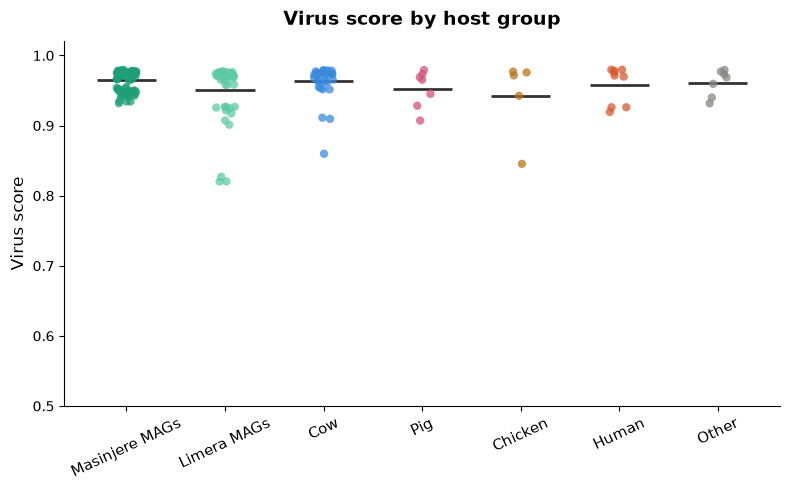

/tmp/ipykernel_825665/1902277262.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=per_genome, x='host_group', y='n_proviruses',
/tmp/ipykernel_825665/1902277262.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(data=per_genome, x='host_group', y='n_proviruses',


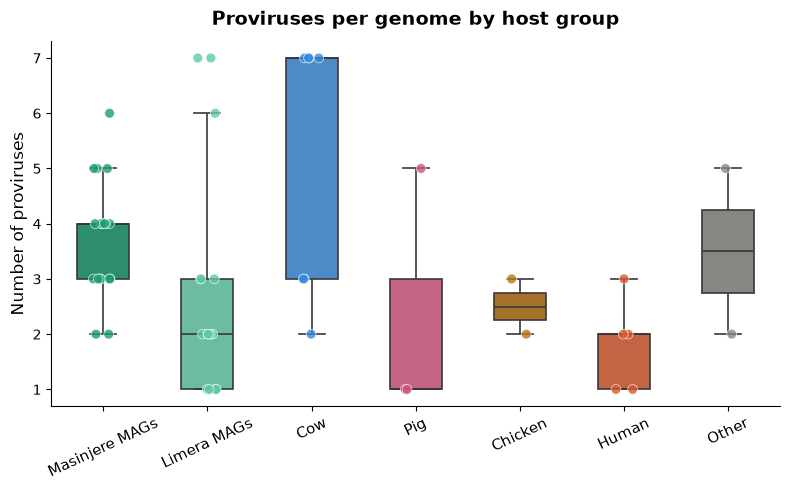

    Host group  Total genomes  With virus  With plasmid  % virus  % plasmid
       Chicken              2           2             0    100.0        0.0
           Cow              7           7             0    100.0        0.0
         Human             11           5             4     45.5       36.4
   Limera MAGs             16          16             0    100.0        0.0
Masinjere MAGs             20          20             0    100.0        0.0
         Other              2           2             0    100.0        0.0
           Pig              3           3             1    100.0       33.3


In [9]:
group_colors = {
    'Masinjere MAGs': '#1D9E75',
    'Limera MAGs': '#5DCAA5',
    'Cow': '#378ADD',
    'Human': '#D85A30',
    'Pig': '#D4537E',
    'Chicken': '#BA7517',
    'Other': '#888780'
}
order = ['Masinjere MAGs', 'Limera MAGs', 'Cow', 'Pig', 'Chicken', 'Human', 'Other']
order_present = [g for g in order if g in virus_df['host_group'].unique()]

# ── 1. Virus score strip plot ──────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 5))
fig.patch.set_facecolor('white')

sns.stripplot(data=virus_df, x='host_group', y='virus_score',
              ax=ax, order=order_present,
              palette=group_colors, size=6, alpha=0.75, jitter=True)

for i, group in enumerate(order_present):
    mean_val = virus_df[virus_df['host_group'] == group]['virus_score'].mean()
    ax.hlines(mean_val, i - 0.3, i + 0.3, colors='#333333', linewidth=2)

ax.set_title('Virus score by host group', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('')
ax.set_ylabel('Virus score', fontsize=12)
ax.set_ylim(0.5, 1.02)
ax.tick_params(axis='x', rotation=25, labelsize=11)
ax.spines[['top', 'right']].set_visible(False)
ax.set_facecolor('white')

plt.tight_layout()
plt.savefig('/home/ottena/mags_project/genomad_analysis/virus_score.png', dpi=150, bbox_inches='tight')
plt.show()

# ── 2. Provirus count boxplot + strip ─────────────────────────────────
per_genome = virus_df.groupby(['genome', 'host_group']).size().reset_index(name='n_proviruses')

fig, ax = plt.subplots(figsize=(8, 5))
fig.patch.set_facecolor('white')

sns.boxplot(data=per_genome, x='host_group', y='n_proviruses',
            order=order_present, palette=group_colors,
            width=0.5, linewidth=1.2, fliersize=0, ax=ax)
sns.stripplot(data=per_genome, x='host_group', y='n_proviruses',
              order=order_present, palette=group_colors,
              size=7, alpha=0.8, jitter=True, ax=ax,
              linewidth=0.5, edgecolor='white')

ax.set_title('Proviruses per genome by host group', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('')
ax.set_ylabel('Number of proviruses', fontsize=12)
ax.tick_params(axis='x', rotation=25, labelsize=11)
ax.spines[['top', 'right']].set_visible(False)
ax.set_facecolor('white')

plt.tight_layout()
plt.savefig('/home/ottena/mags_project/genomad_analysis/provirus_counts.png', dpi=150, bbox_inches='tight')
plt.show()

# ── 3. Presence/absence summary table ─────────────────────────────────
summary = pa_data.groupby('host_group').agg(
    total_genomes=('original_name', 'count'),
    genomes_with_virus=('has_virus', 'sum'),
    genomes_with_plasmid=('has_plasmid', 'sum')
).reset_index()
summary['pct_virus'] = (summary['genomes_with_virus'] / summary['total_genomes'] * 100).round(1)
summary['pct_plasmid'] = (summary['genomes_with_plasmid'] / summary['total_genomes'] * 100).round(1)
summary.columns = ['Host group', 'Total genomes', 'With virus', 'With plasmid', '% virus', '% plasmid']
print(summary.to_string(index=False))

In [10]:
# Fix 1: move table out of the figure - just print it in a separate cell
summary = pa_data.groupby('host_group').agg(
    total_genomes=('original_name', 'count'),
    genomes_with_virus=('has_virus', 'sum'),
    genomes_with_plasmid=('has_plasmid', 'sum')
).reset_index()
summary['pct_virus'] = (summary['genomes_with_virus'] / summary['total_genomes'] * 100).round(1)
summary['pct_plasmid'] = (summary['genomes_with_plasmid'] / summary['total_genomes'] * 100).round(1)
summary.columns = ['Host group', 'Total genomes', 'With virus', 'With plasmid', '% virus', '% plasmid']
summary

,Host group,Total genomes,With virus,With plasmid,% virus,% plasmid
0,Chicken,2,2,0,100.0,0.0
1,Cow,7,7,0,100.0,0.0
2,Human,11,5,4,45.5,36.4
3,Limera MAGs,16,16,0,100.0,0.0
4,Masinjere MAGs,20,20,0,100.0,0.0
5,Other,2,2,0,100.0,0.0
6,Pig,3,3,1,100.0,33.3


/tmp/ipykernel_825665/2049424416.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=per_genome, x='host_group', y='n_proviruses',
/tmp/ipykernel_825665/2049424416.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(data=per_genome, x='host_group', y='n_proviruses',


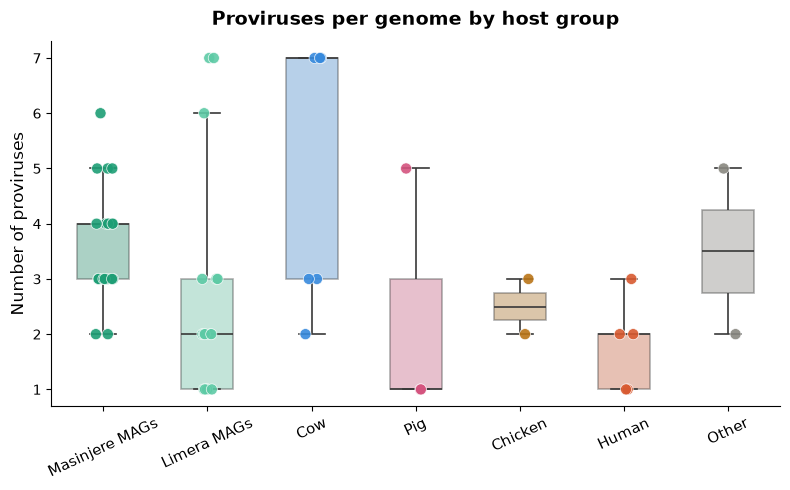

In [11]:
# Fix 2: dots on top of boxes
fig, ax = plt.subplots(figsize=(8, 5))
fig.patch.set_facecolor('white')

sns.boxplot(data=per_genome, x='host_group', y='n_proviruses',
            order=order_present, palette=group_colors,
            width=0.5, linewidth=1.2, fliersize=0, ax=ax,
            boxprops=dict(alpha=0.4))  # make boxes transparent so dots show
sns.stripplot(data=per_genome, x='host_group', y='n_proviruses',
              order=order_present, palette=group_colors,
              size=8, alpha=0.9, jitter=True, ax=ax,
              linewidth=0.5, edgecolor='white', zorder=10)

ax.set_title('Proviruses per genome by host group', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('')
ax.set_ylabel('Number of proviruses', fontsize=12)
ax.tick_params(axis='x', rotation=25, labelsize=11)
ax.spines[['top', 'right']].set_visible(False)
ax.set_facecolor('white')

plt.tight_layout()
plt.savefig('/home/ottena/mags_project/genomad_analysis/provirus_counts.png', dpi=150, bbox_inches='tight')
plt.show()

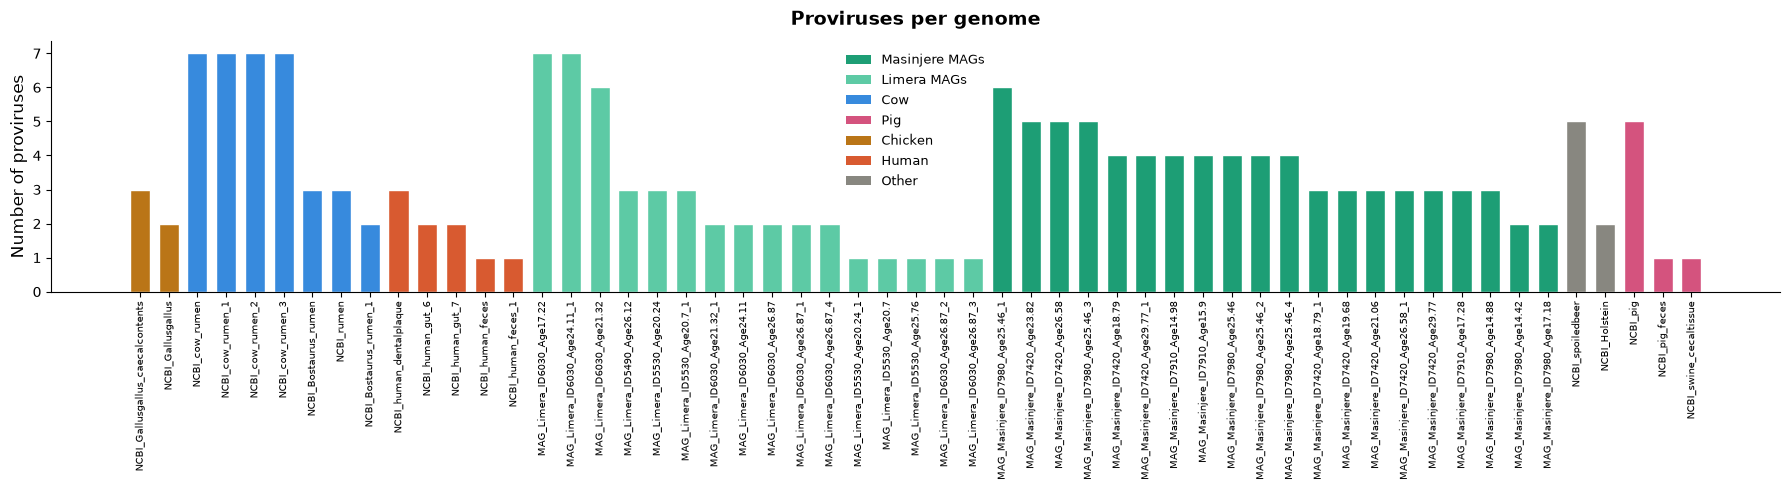

In [13]:
per_genome = virus_df.groupby(['plot_label', 'host_group']).size().reset_index(name='n_proviruses')
per_genome = per_genome.sort_values(['host_group', 'n_proviruses'], ascending=[True, False])

fig, ax = plt.subplots(figsize=(18, 5))
fig.patch.set_facecolor('white')

ax.bar(per_genome['plot_label'], per_genome['n_proviruses'],
       color=[group_colors[g] for g in per_genome['host_group']],
       edgecolor='white', width=0.7)

ax.set_title('Proviruses per genome', fontsize=14, fontweight='bold', pad=12)
ax.set_ylabel('Number of proviruses', fontsize=12)
ax.set_xlabel('')
ax.tick_params(axis='x', rotation=90, labelsize=7)
ax.spines[['top', 'right']].set_visible(False)
ax.set_facecolor('white')

from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=group_colors[g], label=g) 
                   for g in order if g in per_genome['host_group'].values]
ax.legend(handles=legend_elements, fontsize=9, frameon=False)

plt.tight_layout()
plt.savefig('/home/ottena/mags_project/genomad_analysis/provirus_per_genome.png', dpi=150, bbox_inches='tight')
plt.show()